# 02_ML_Analysis.ipynb
Customer Segmentation and Sales Forecasting analysis

In [1]:
import pandas as pd
from pathlib import Path
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'data' / 'processed').exists())
DATA = PROJECT_ROOT / 'data' / 'processed'
cust = pd.read_csv(DATA / 'customer_features.csv')
monthly = pd.read_csv(DATA / 'monthly_sales.csv')
cust.head()


,Customer_ID,Total_Spend,Total_Orders,Avg_Order_Value,Total_Profit,Total_Quantity,First_Purchase,Last_Purchase,Recency_Days,Frequency,CLV
0,C1000,3082.75,10,237.134615,1302.04,22,2020-02-03,2023-10-03,88,0.007013,1302.04
1,C1001,2919.37,4,324.374444,1204.31,17,2020-06-18,2022-05-19,590,0.003101,1204.31
2,C1002,3490.50,8,317.318182,1245.00,25,2020-05-28,2023-08-31,121,0.006102,1245.00
3,C1003,3910.56,5,355.505455,1867.33,24,2020-01-26,2023-02-21,312,0.003487,1867.33
4,C1004,5597.81,12,310.989444,2217.59,36,2020-01-11,2023-08-26,126,0.008282,2217.59


## 1. Customer segmentation
We use scaled customer-level spend, order frequency, profit, and recency features. K-Means is interpretable and suitable for grouping customers without pre-existing labels.


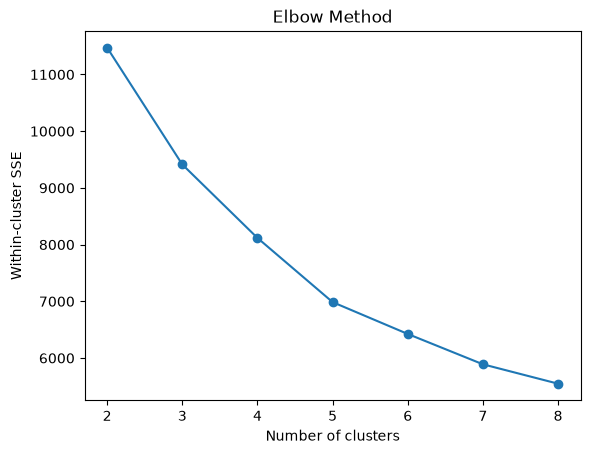

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

cluster_features = ['Total_Spend', 'Total_Orders', 'Avg_Order_Value', 'Total_Profit', 'Recency_Days', 'Frequency']
X = cust[cluster_features].fillna(0)
X_scaled = StandardScaler().fit_transform(X)

inertias = []
for k in range(2, 9):
    inertias.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_)
plt.plot(range(2, 9), inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Within-cluster SSE')
plt.show()


In [3]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
cust['Cluster'] = kmeans.fit_predict(X_scaled)
cluster_profile = cust.groupby('Cluster')[cluster_features].mean().round(2)
cluster_counts = cust['Cluster'].value_counts().sort_index().rename('Customers')
cluster_profile.join(cluster_counts)


,Total_Spend,Total_Orders,Avg_Order_Value,Total_Profit,Recency_Days,Frequency,Customers
Cluster,,,,,,,
0,6103.84,10.00,369.24,2500.28,133.11,0.01,698
1,2600.55,6.21,277.38,1058.95,148.51,0.01,1030
2,1831.87,3.63,322.21,742.32,553.29,0.00,479
3,4282.70,6.16,439.77,1756.03,185.58,0.01,792


## 2. Monthly sales forecasting
The final 12 months are held out chronologically. Random train/test splitting is avoided because it would leak future patterns into training.


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

monthly['Order_Date'] = pd.to_datetime(monthly['Order_Date'])
if not {'t', 'lag_1', 'lag_2', 'Sales'}.issubset(monthly.columns):
    monthly['t'] = np.arange(len(monthly))
    monthly['lag_1'] = monthly['Monthly_Sales'].shift(1)
    monthly['lag_2'] = monthly['Monthly_Sales'].shift(2)
    monthly['Sales'] = monthly['Monthly_Sales']
monthly = monthly.dropna().reset_index(drop=True)
features = ['t', 'lag_1', 'lag_2']
train, test = monthly.iloc[:-12], monthly.iloc[-12:]
models = {'LinearRegression': LinearRegression(), 'RandomForest': RandomForestRegressor(n_estimators=200, random_state=42)}
results = []
for name, model in models.items():
    model.fit(train[features], train['Sales'])
    prediction = model.predict(test[features])
    results.append({'model': name, 'MAE': mean_absolute_error(test['Sales'], prediction), 'RMSE': np.sqrt(mean_squared_error(test['Sales'], prediction)), 'R2': r2_score(test['Sales'], prediction)})
pd.DataFrame(results)


,model,MAE,RMSE,R2
0,LinearRegression,12783.376941,15090.718147,-0.509211
1,RandomForest,17708.686967,19701.548649,-1.572356
